# Budynki i wskaźnik ryzyka — wariant bez kopalni

Notatnik powtarza analizy budynków z `EGMS_buildings_analysis.ipynb` i `ryzyko_budynkow_wrazliwosc.ipynb` na wynikach wariantu **bez kopalni** (`EGMS_bez_kopalni_analysis.ipynb`) i porównuje je z wariantem pełnym.

Metoda jest taka sama jak w wariancie pełnym:

- każdy budynek dostaje najbliższy PS w promieniu `MAX_DISTANCE = 30 m` (przy równych odległościach – PS o wyższym `anomaly_score`),
- `ryzyko = zagrożenie × podatność`, gdzie zagrożenie to średnia rang percentylowych osiadania i `anomaly_score`, a podatność – średnia rangi wysokości i typu budynku (mieszkalny = 1, niemieszkalny = 0,5),
- budynki najwyższego ryzyka to 5% budynków o najwyższym wskaźniku.

Różnica polega wyłącznie na zbiorze PS: punkty odkrywki i zwałowiska są usunięte, a `anomaly_score` pochodzi z modelu wytrenowanego bez nich.

**Dane wejściowe:**

- `EGMS_Turow_bez_kopalni_U_results.csv` – PS bez kopalni (`EGMS_bez_kopalni_analysis.ipynb`),
- `EGMS_Turow_U_results.csv` – PS wariantu pełnego (do porównania),
- `budynki_Turow.gpkg` – obrysy budynków EUBUCCO,
- `budynki_ryzyko.gpkg` – wskaźnik ryzyka wariantu pełnego (`ryzyko_budynkow_wrazliwosc.ipynb`).

**Wyniki:**

- `budynki_EGMS_bez_kopalni_results.gpkg` – wszystkie budynki z najbliższym PS (układ jak `budynki_EGMS_results.gpkg`),
- `budynki_ryzyko_bez_kopalni.gpkg` – budynki z PS i wskaźnikiem ryzyka (układ jak `budynki_ryzyko.gpkg`) oraz kolumnami porównania z wariantem pełnym.

In [1]:
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

# Wczytanie danych

Budynki przygotowujemy tak samo jak w notatnikach wariantu pełnego (usunięcie powtarzających się geometrii, identyfikatory `building_id` nadawane w tej samej kolejności), więc `building_id` jest zgodny między wariantami.

In [2]:
def wczytaj_ps(plik):
    ps = pd.read_csv(plik)
    return gpd.GeoDataFrame(
        ps.drop(columns=["easting", "northing"]),
        geometry=gpd.points_from_xy(ps["easting"], ps["northing"]),
        crs="EPSG:3035"
    )


ps_bk = wczytaj_ps("EGMS_Turow_bez_kopalni_U_results.csv")
ps_pelny = wczytaj_ps("EGMS_Turow_U_results.csv")

budynki = gpd.read_file("budynki_Turow.gpkg")
budynki = budynki.drop_duplicates(subset="geometry").reset_index(drop=True)
budynki["building_id"] = np.arange(1, len(budynki) + 1)
budynki = budynki.to_crs(ps_bk.crs)

print("PS bez kopalni:", len(ps_bk))
print("PS wariant pełny:", len(ps_pelny))
print("Budynki:", len(budynki))

PS bez kopalni: 5143
PS wariant pełny: 6268
Budynki: 39156


# CZĘŚĆ 1 — Przypisanie PS do budynków

In [3]:
MAX_DISTANCE = 30  # [m]

ps_cols = ["pid", "mean_velocity", "acceleration", "trend_change", "anomaly_score", "anomaly", "cluster", "rmse_ts", "geometry"]


def przypisz_ps(ps_gdf, max_distance):
    wynik = gpd.sjoin_nearest(
        budynki,
        ps_gdf[ps_cols],
        how="left",
        max_distance=max_distance,
        distance_col="distance_PS"
    )

    wynik = (
        wynik
        .sort_values(
            ["building_id", "distance_PS", "anomaly_score"],
            ascending=[True, True, False],
            na_position="last"
        )
        .drop_duplicates(subset="building_id", keep="first")
        .drop(columns="index_right")
        .reset_index(drop=True)
    )
    wynik["has_PS_30m"] = wynik["pid"].notna()

    return wynik


bud_bk = przypisz_ps(ps_bk, MAX_DISTANCE)
bud_pelny = przypisz_ps(ps_pelny, MAX_DISTANCE)

print("Budynki z PS (wariant pełny):", bud_pelny["has_PS_30m"].sum())
print("Budynki z PS (bez kopalni):", bud_bk["has_PS_30m"].sum())

Budynki z PS (wariant pełny): 15376
Budynki z PS (bez kopalni): 15291


Wariant pełny odtwarza liczbę budynków z PS z `EGMS_buildings_analysis.ipynb` (15 376).

## Które budynki straciły PS?

Najbliższy PS budynku zmienia się tylko wtedy, gdy w wariancie pełnym był to punkt kopalni. Taki budynek albo dostaje inny PS w promieniu 30 m, albo zostaje bez PS.

In [4]:
pid_kopalni = set(ps_pelny["pid"]) - set(ps_bk["pid"])

zmiany = pd.DataFrame({
    "building_id": bud_pelny["building_id"],
    "kraj": bud_pelny["kraj"],
    "type": bud_pelny["type"],
    "PS_pelny": bud_pelny["has_PS_30m"],
    "PS_kopalni_pelny": bud_pelny["pid"].isin(pid_kopalni),
    "PS_bk": bud_bk["has_PS_30m"].to_numpy(),
})
assert (bud_pelny["building_id"].to_numpy() == bud_bk["building_id"].to_numpy()).all()

zmiany["status"] = np.select(
    [
        zmiany["PS_kopalni_pelny"] & zmiany["PS_bk"],
        zmiany["PS_kopalni_pelny"],
        zmiany["PS_pelny"],
    ],
    ["PS kopalni → inny PS", "PS kopalni → brak PS", "PS bez zmian"],
    default="brak PS w obu wariantach"
)

pd.crosstab(zmiany["status"], zmiany["kraj"], margins=True)

kraj,CZ,DE,PL,All
status,,,,
PS bez zmian,2762,9052,3477,15291
PS kopalni → brak PS,0,0,85,85
brak PS w obu wariantach,4494,14049,5237,23780
All,7256,23101,8799,39156


In [5]:
# Typy budynków, które w wariancie pełnym miały PS kopalni
pd.crosstab(
    zmiany.loc[zmiany["PS_kopalni_pelny"], "type"],
    zmiany.loc[zmiany["PS_kopalni_pelny"], "status"],
    margins=True
)

status,PS kopalni → brak PS,All
type,,
non-residential,76,76
residential,9,9
All,85,85


## Warstwa wynikowa budynków

Układ kolumn jak w `budynki_EGMS_results.gpkg`.

In [6]:
kolumny_bud = list(gpd.read_file("budynki_EGMS_results.gpkg", rows=1).columns)

bud_bk[kolumny_bud].to_file(
    "budynki_EGMS_bez_kopalni_results.gpkg",
    layer="budynki_EGMS",
    driver="GPKG"
)

print("Zapisano: budynki_EGMS_bez_kopalni_results.gpkg")
print("Budynki:", len(bud_bk), "| z PS do 30 m:", bud_bk["has_PS_30m"].sum())

Zapisano: budynki_EGMS_bez_kopalni_results.gpkg
Budynki: 39156 | z PS do 30 m: 15291


# CZĘŚĆ 2 — Wskaźnik ryzyka

Funkcja `oblicz_ryzyko()` jest identyczna jak w `ryzyko_budynkow_wrazliwosc.ipynb`. Rangi percentylowe są względne, więc w wariancie bez kopalni budynki są porządkowane tylko na tle budynków z PS spoza kopalni, a `anomaly_score` pochodzi z nowego modelu.

In [7]:
def oblicz_ryzyko(df):
    # Tylko budynki z przypisanym PS
    df = df.dropna(subset=["pid"]).copy()

    # Zagrożenie – na podstawie punktu PS
    df["z_osiadanie"] = (-df["mean_velocity"]).rank(pct=True)
    df["z_anomalia"] = df["anomaly_score"].rank(pct=True)
    df["zagrozenie"] = (df["z_osiadanie"] + df["z_anomalia"]) / 2

    # Podatność – na podstawie cech budynku
    df["p_wysokosc"] = df["height"].rank(pct=True)
    df["p_typ"] = np.where(df["type"] == "residential", 1.0, 0.5)
    df["podatnosc"] = (df["p_wysokosc"] + df["p_typ"]) / 2

    df["ryzyko"] = df["zagrozenie"] * df["podatnosc"]

    return df


ryzyko_bk = oblicz_ryzyko(bud_bk)

prog_ryzyka = ryzyko_bk["ryzyko"].quantile(0.95)
ryzyko_bk["wysokie_ryzyko"] = ryzyko_bk["ryzyko"] >= prog_ryzyka

print("Budynki ze wskaźnikiem ryzyka:", len(ryzyko_bk))
print("Próg ryzyka (95. percentyl):", round(prog_ryzyka, 3))
print("Budynki najwyższego ryzyka:", ryzyko_bk["wysokie_ryzyko"].sum())

ryzyko_bk[["zagrozenie", "podatnosc", "ryzyko"]].describe().round(3)

Budynki ze wskaźnikiem ryzyka: 15291
Próg ryzyka (95. percentyl): 0.743
Budynki najwyższego ryzyka: 765


,zagrozenie,podatnosc,ryzyko
count,15291.000,15291.000,15291.000
mean,0.500,0.629,0.315
std,0.246,0.236,0.206
min,0.105,0.250,0.029
25%,0.276,0.400,0.153
50%,0.475,0.639,0.260
75%,0.712,0.848,0.432
max,1.000,1.000,0.981


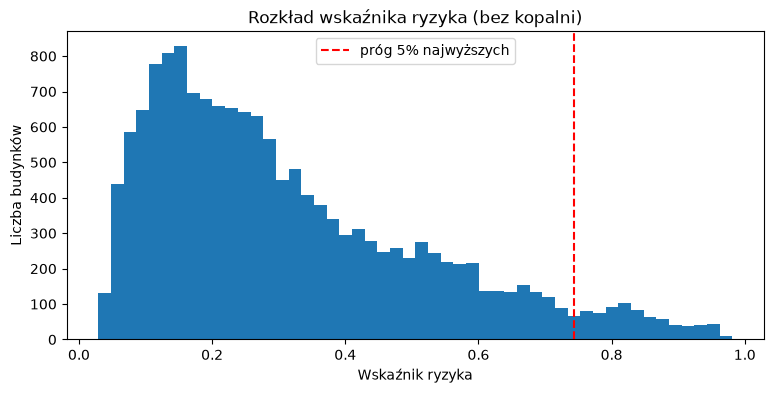

In [8]:
plt.figure(figsize=(9, 4))
plt.hist(ryzyko_bk["ryzyko"], bins=50)
plt.axvline(prog_ryzyka, color="red", linestyle="--", label="próg 5% najwyższych")
plt.xlabel("Wskaźnik ryzyka")
plt.ylabel("Liczba budynków")
plt.title("Rozkład wskaźnika ryzyka (bez kopalni)")
plt.legend()
plt.show()

In [9]:
# 10 budynków o najwyższym wskaźniku ryzyka
ryzyko_bk.nlargest(10, "ryzyko")[
    ["building_id", "kraj", "type", "height", "mean_velocity", "anomaly_score",
     "cluster", "distance_PS", "zagrozenie", "podatnosc", "ryzyko"]
].round(3)

,building_id,kraj,type,height,mean_velocity,anomaly_score,cluster,distance_PS,zagrozenie,podatnosc,ryzyko
9653,9654,DE,residential,19.1,-9.2,0.542,0.0,14.465,0.987,0.994,0.981
28401,28402,DE,residential,20.9,-8.0,0.527,0.0,0.000,0.983,0.997,0.980
37178,37179,DE,residential,19.0,-8.0,0.527,0.0,29.553,0.983,0.994,0.977
29907,29908,DE,residential,16.7,-8.4,0.545,0.0,27.045,0.987,0.984,0.971
36974,36975,DE,residential,18.3,-7.7,0.518,0.0,0.000,0.977,0.992,0.970
21421,21422,DE,residential,18.1,-6.8,0.543,0.0,22.047,0.976,0.991,0.968
21422,21423,DE,residential,18.0,-6.8,0.543,0.0,22.292,0.976,0.991,0.967
21423,21424,DE,residential,18.0,-6.8,0.543,0.0,23.276,0.976,0.991,0.967
17080,17081,DE,residential,19.7,-7.1,0.509,0.0,27.851,0.967,0.996,0.963
31919,31920,DE,residential,16.5,-7.8,0.523,0.0,17.035,0.981,0.982,0.963


## Ryzyko a kraj, typ budynku i klaster PS

In [10]:
def podsumowanie(df, kolumna):
    tab = df.groupby(kolumna).agg(
        n_budynkow=("building_id", "count"),
        n_wysokie_ryzyko=("wysokie_ryzyko", "sum"),
        mediana_velocity=("mean_velocity", "median"),
        mediana_ryzyka=("ryzyko", "median"),
    )
    tab["procent_wysokie_ryzyko"] = tab["n_wysokie_ryzyko"] / tab["n_budynkow"] * 100
    tab["udzial_w_grupie_%"] = tab["n_wysokie_ryzyko"] / tab["n_wysokie_ryzyko"].sum() * 100
    return tab.round(2)


podsumowanie(ryzyko_bk, "kraj")

,n_budynkow,n_wysokie_ryzyko,mediana_velocity,mediana_ryzyka,procent_wysokie_ryzyko,udzial_w_grupie_%
kraj,,,,,,
CZ,2762,6,-0.8,0.26,0.22,0.78
DE,9052,737,-1.2,0.29,8.14,96.34
PL,3477,22,-0.6,0.21,0.63,2.88


In [11]:
podsumowanie(ryzyko_bk, "type")

,n_budynkow,n_wysokie_ryzyko,mediana_velocity,mediana_ryzyka,procent_wysokie_ryzyko,udzial_w_grupie_%
type,,,,,,
non-residential,7414,0,-0.9,0.19,0.00,0.0
residential,7877,765,-0.8,0.37,9.71,100.0


In [12]:
# Klastry wariantu bez kopalni: 0 – osiadanie ok. −4,7 mm/rok (Zittau, Hrádek),
# 1 – spowolnienie, 2 – przyspieszenie w ostatnich 12 mies., 3 – stabilne
podsumowanie(ryzyko_bk, "cluster")

,n_budynkow,n_wysokie_ryzyko,mediana_velocity,mediana_ryzyka,procent_wysokie_ryzyko,udzial_w_grupie_%
cluster,,,,,,
0.0,2762,710,-4.6,0.57,25.71,92.81
1.0,1274,14,-2.5,0.38,1.10,1.83
2.0,1706,35,-0.4,0.32,2.05,4.58
3.0,9549,6,-0.6,0.19,0.06,0.78


# CZĘŚĆ 3 — Porównanie z wariantem pełnym

Wariant pełny wczytujemy z `budynki_ryzyko.gpkg`. Porównujemy listy budynków najwyższego ryzyka i wartości wskaźnika dla budynków obecnych w obu wariantach.

In [13]:
ryzyko_pelny = gpd.read_file("budynki_ryzyko.gpkg")

top_pelny = set(ryzyko_pelny.loc[ryzyko_pelny["wysokie_ryzyko"], "building_id"])
top_bk = set(ryzyko_bk.loc[ryzyko_bk["wysokie_ryzyko"], "building_id"])

print("Najwyższe ryzyko – wariant pełny:", len(top_pelny))
print("Najwyższe ryzyko – bez kopalni:", len(top_bk))
print("  …wspólne:", len(top_pelny & top_bk))
print("  …tylko w wariancie pełnym:", len(top_pelny - top_bk))
print("  …nowe:", len(top_bk - top_pelny))

wspolne = ryzyko_bk[["building_id", "ryzyko"]].merge(
    ryzyko_pelny[["building_id", "ryzyko"]], on="building_id", suffixes=("", "_pelny")
)
print()
print("Budynki ze wskaźnikiem w obu wariantach:", len(wspolne))
print("Korelacja rangowa wskaźnika (Spearman):",
      round(wspolne["ryzyko"].corr(wspolne["ryzyko_pelny"], method="spearman"), 3))

Najwyższe ryzyko – wariant pełny: 769
Najwyższe ryzyko – bez kopalni: 765
  …wspólne: 730
  …tylko w wariancie pełnym: 39
  …nowe: 35

Budynki ze wskaźnikiem w obu wariantach: 15291


Korelacja rangowa wskaźnika (Spearman): 0.988


In [14]:
# Dlaczego budynki wypadły z listy najwyższego ryzyka?
wypadly = ryzyko_pelny[ryzyko_pelny["building_id"].isin(top_pelny - top_bk)][["building_id", "kraj", "pid", "ryzyko"]]
wypadly = wypadly.merge(
    ryzyko_bk[["building_id", "ryzyko"]], on="building_id", how="left", suffixes=("_pelny", "_bk")
)
wypadly["przyczyna"] = np.select(
    [wypadly["pid"].isin(pid_kopalni) & wypadly["ryzyko_bk"].isna(),
     wypadly["pid"].isin(pid_kopalni)],
    ["PS kopalni → brak PS", "PS kopalni → inny PS"],
    default="ten sam PS, niższa ranga"
)

pd.crosstab(wypadly["przyczyna"], wypadly["kraj"], margins=True)

kraj,CZ,DE,PL,All
przyczyna,,,,
"ten sam PS, niższa ranga",20,15,4,39
All,20,15,4,39


In [15]:
# Lista najwyższego ryzyka w obu wariantach według krajów
pd.DataFrame({
    "wariant pełny": ryzyko_pelny[ryzyko_pelny["wysokie_ryzyko"]]["kraj"].value_counts(),
    "bez kopalni": ryzyko_bk[ryzyko_bk["wysokie_ryzyko"]]["kraj"].value_counts(),
}).fillna(0).astype(int)

,wariant pełny,bez kopalni
kraj,,
CZ,26,6
DE,719,737
PL,24,22


## Mapa wskaźnika ryzyka

Budynki pokazujemy jako punkty (środki obrysów). Czarne obwódki – budynki najwyższego ryzyka, szare punkty – budynki bez PS w promieniu 30 m.

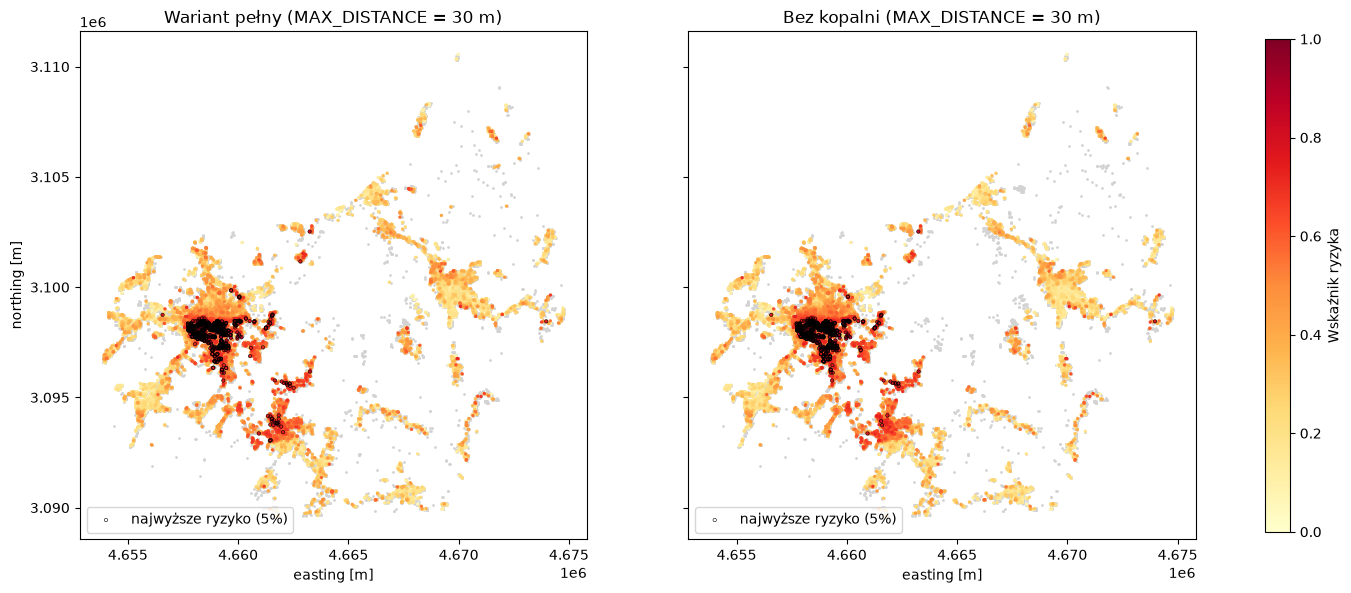

In [16]:
srodki_wszystkie = budynki.geometry.centroid

fig, axes = plt.subplots(1, 2, figsize=(18, 8), sharex=True, sharey=True)

for ax, df_r, tytul in [
    (axes[0], ryzyko_pelny, "Wariant pełny"),
    (axes[1], ryzyko_bk, "Bez kopalni"),
]:
    df_r = df_r.sort_values("ryzyko")
    srodki = df_r.geometry.centroid
    top = df_r["wysokie_ryzyko"].to_numpy()

    ax.scatter(srodki_wszystkie.x, srodki_wszystkie.y, s=1, color="lightgrey")
    sc = ax.scatter(srodki.x, srodki.y, c=df_r["ryzyko"], s=2, cmap="YlOrRd", vmin=0, vmax=1)
    ax.scatter(srodki.x[top], srodki.y[top], s=6, facecolors="none", edgecolors="black", linewidths=0.4,
               label="najwyższe ryzyko (5%)")
    ax.set_aspect("equal")
    ax.set_xlabel("easting [m]")
    ax.set_title(f"{tytul} (MAX_DISTANCE = {MAX_DISTANCE} m)")
    ax.legend(loc="lower left")

axes[0].set_ylabel("northing [m]")
plt.colorbar(sc, ax=axes, label="Wskaźnik ryzyka", shrink=0.8)
plt.show()

# CZĘŚĆ 4 — Wrażliwość na `MAX_DISTANCE`

Ten sam test co w `ryzyko_budynkow_wrazliwosc.ipynb`, ale dla wariantu bez kopalni: porównujemy listy najwyższego ryzyka tej samej długości co przy 30 m.

In [17]:
progi = [10, 20, 30, 50, 70, 100]

n_top = len(top_bk)
top_30 = set(ryzyko_bk.nlargest(n_top, "ryzyko")["building_id"])

wiersze = []
for d in progi:
    wynik_d = oblicz_ryzyko(przypisz_ps(ps_bk, d))
    top_d = wynik_d.nlargest(n_top, "ryzyko")

    wiersze.append({
        "max_distance": d,
        "n_budynkow_z_PS": len(wynik_d),
        "procent_budynkow_z_PS": len(wynik_d) / len(budynki) * 100,
        "budynki_na_PS": len(wynik_d) / wynik_d["pid"].nunique(),
        "mediana_odleglosci": wynik_d["distance_PS"].median(),
        "procent_wspolnych_top": len(top_30 & set(top_d["building_id"])) / n_top * 100,
        "procent_top_PS_ponad_30m": (top_d["distance_PS"] > 30).mean() * 100,
    })

pd.DataFrame(wiersze).round(2)

,max_distance,n_budynkow_z_PS,procent_budynkow_z_PS,budynki_na_PS,mediana_odleglosci,procent_wspolnych_top,procent_top_PS_ponad_30m
0,10,3067,7.83,1.69,5.18,18.69,0.00
1,20,8050,20.56,2.87,12.50,52.55,0.00
2,30,15291,39.05,4.49,19.39,100.00,0.00
3,50,33346,85.16,8.17,31.62,47.97,52.03
4,70,37809,96.56,9.00,34.04,44.97,55.03
5,100,38314,97.85,9.09,34.31,44.71,55.29


# Eksport do QGIS

Kolumny jak w `budynki_ryzyko.gpkg` oraz dodatkowo:

- `ryzyko_pelny`, `wysokie_ryzyko_pelny` – wynik wariantu pełnego dla tego samego budynku (puste, jeśli w wariancie pełnym budynek nie miał PS),
- `zmiana_listy` – `wspólny`, `nowy` lub pusty (budynek spoza listy w obu wariantach).

Budynki, które wypadły z listy, bo straciły PS, nie występują w tej warstwie – są w `budynki_ryzyko.gpkg` (`wysokie_ryzyko = True`) i nie mają wiersza tutaj.

In [18]:
export_cols = list(ryzyko_pelny.columns)
export_cols.remove("geometry")

eksport = ryzyko_bk[export_cols + ["geometry"]].merge(
    ryzyko_pelny[["building_id", "ryzyko", "wysokie_ryzyko"]].rename(
        columns={"ryzyko": "ryzyko_pelny", "wysokie_ryzyko": "wysokie_ryzyko_pelny"}
    ),
    on="building_id",
    how="left"
)
eksport["zmiana_listy"] = np.select(
    [eksport["wysokie_ryzyko"] & (eksport["wysokie_ryzyko_pelny"] == True),
     eksport["wysokie_ryzyko"]],
    ["wspólny", "nowy"],
    default=""
)
eksport = gpd.GeoDataFrame(eksport, geometry="geometry", crs=budynki.crs)

eksport.to_file("budynki_ryzyko_bez_kopalni.gpkg", layer="budynki_ryzyko", driver="GPKG")

print("Zapisano: budynki_ryzyko_bez_kopalni.gpkg")
print(eksport["zmiana_listy"].value_counts())

Zapisano: budynki_ryzyko_bez_kopalni.gpkg
zmiana_listy
           14526
wspólny      730
nowy          35
Name: count, dtype: int64


# Wnioski

## Przypisanie PS

- Usunięcie kopalni (maska odkrywki i zwałowiska z folderu `mask/`) prawie nie zmienia przypisania: 15 291 budynków ma PS w promieniu 30 m (wcześniej 15 376). PS straciło tylko **85 budynków – wszystkie w Polsce, w tym 76 niemieszkalnych**, czyli głównie zabudowa w obrębie kopalni. Żaden budynek nie dostał innego PS – najbliższy punkt spoza kopalni leżał zawsze dalej niż 30 m.
- Zabudowa mieszkaniowa praktycznie nie sąsiadowała bezpośrednio z punktami kopalni (9 budynków), więc wskaźnik ryzyka dla budynków mieszkalnych nie był w wariancie pełnym zniekształcony przez samą kopalnię.

## Wskaźnik ryzyka

- Lista budynków najwyższego ryzyka (5%, 765 budynków) jest w 95% taka sama jak w wariancie pełnym (730 wspólnych), a ranking wskaźnika jest niemal identyczny (Spearman 0,99).
- 39 budynków wypadło z listy, a 35 doszło. Żaden nie wypadł z powodu utraty PS – wszystkie zmiany wynikają z nowego `anomaly_score` (model wytrenowany bez kopalni). Najwięcej zmian dotyczy Czech: liczba budynków najwyższego ryzyka spadła tam z 26 do 6.
- Grupa najwyższego ryzyka jest jeszcze bardziej skupiona w Niemczech: **96%** (wcześniej 93%), czyli 8,1% budynków z PS po stronie niemieckiej wobec 0,6% w Polsce i 0,2% w Czechach. Nadal tworzą ją wyłącznie budynki mieszkalne.
- **93% budynków najwyższego ryzyka leży przy PS klastra 0** (systematyczne osiadanie ok. −4,8 mm/rok w Zittau i Hrádku nad Nisou); co czwarty budynek przypisany do tego klastra należy do grupy najwyższego ryzyka. Wariant bez kopalni wyraźnie wskazuje więc, że o ryzyku zabudowy decyduje osiadanie w Zittau, a nie sama kopalnia.

## Wrażliwość na `MAX_DISTANCE`

- Zależność od progu jest praktycznie taka sama jak w wariancie pełnym: przy 50 m zostaje na liście 48% budynków z listy dla 30 m, przy 20 m – 53%. Rekomendacja 30 m pozostaje bez zmian.

## Wniosek ogólny

Wynik analizy budynków jest **odporny na usunięcie kopalni**. Wymaskowanie odkrywki i zwałowiska zmienia obraz anomalii i klastrów PS (`EGMS_bez_kopalni_analysis.ipynb`), ale lista budynków najwyższego ryzyka prawie się nie zmienia, bo w bezpośrednim sąsiedztwie punktów kopalni prawie nie ma zabudowy mieszkaniowej. Ograniczenia wskaźnika opisane w `ryzyko_budynkow_wrazliwosc.ipynb` (porównywalność wysokości między krajami, przyjęte wagi, względny charakter rang) obowiązują bez zmian.